NAME: ARNAV PUNDIR

SECTION: B

ROLL.NO.: 10

CU ID: CU240251013

## LAB SHEET - 07

=== Dataset Summary ===
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   38                 100                      16
1           2  Female   36                  44                      51
2           3    Male   60                  57                      47
3           4  Female   29                  84                      89
4           5  Female   44                  16                      19

Shape: (200, 5)


Missing values: 0
Rows after removing duplicates: 200


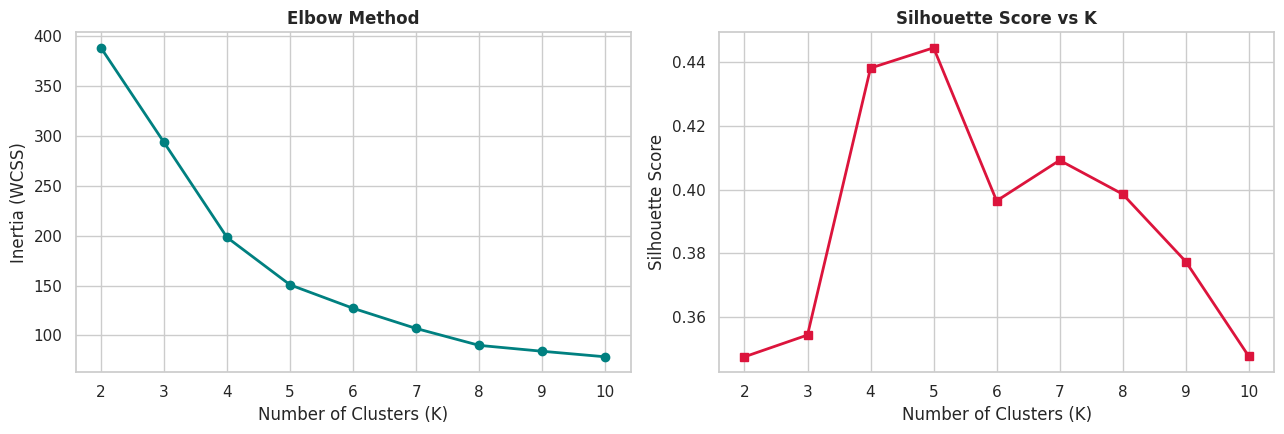

=== Silhouette Scores ===
K =  2 : 0.3475
K =  3 : 0.3544
K =  4 : 0.4382
K =  5 : 0.4446
K =  6 : 0.3965
K =  7 : 0.4092
K =  8 : 0.3986
K =  9 : 0.3775
K = 10 : 0.3477

Optimal number of clusters (K) = 5




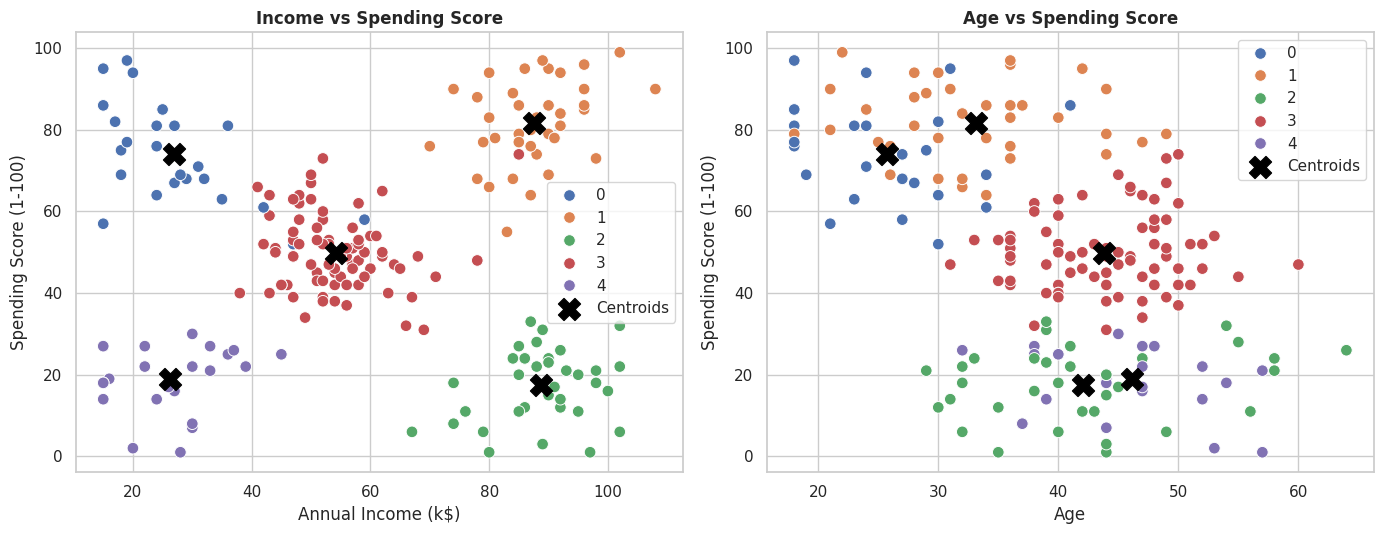

=== Cluster Profiles (average values) ===
          Age  Annual Income (k$)  Spending Score (1-100)  Customers
Cluster                                                             
0        25.7                26.9                    74.0         25
1        33.1                87.6                    81.8         38
2        42.1                88.8                    17.4         35
3        43.8                54.2                    49.8         79
4        46.2                26.2                    18.9         23


=== Customer Segments and Marketing Strategies ===
Cluster 0: Low Income - High Spending (25 customers)
   Strategy: Discounts, combo deals and budget-friendly offers to keep them engaged
Cluster 1: High Income - High Spending (38 customers)
   Strategy: Premium offers, loyalty rewards, early access to new products
Cluster 2: High Income - Low Spending (35 customers)
   Strategy: Personalized promotions to convert their high buying power into sales
Cluster 3: Medium In

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

# Load dataset
rng = np.random.default_rng(42)
segments = [
    (81, 43, 55, 50), (35, 41, 88, 17), (23, 45, 26, 20),
    (39, 33, 87, 82), (22, 25, 25, 79)]
rows = []
for n, a, inc, sp in segments:
    rows.append(pd.DataFrame({
        "Age": rng.normal(a, 8, n).round().clip(18, 70).astype(int),
        "Annual Income (k$)": rng.normal(inc, 8, n).round().clip(15, 137).astype(int),
        "Spending Score (1-100)": rng.normal(sp, 9, n).round().clip(1, 99).astype(int)}))
customer_df = pd.concat(rows, ignore_index=True).sample(frac=1, random_state=42).reset_index(drop=True)
customer_df.insert(0, "CustomerID", np.arange(1, len(customer_df) + 1))
customer_df.insert(1, "Gender", rng.choice(["Male", "Female"], len(customer_df), p=[0.44, 0.56]))

print("=== Dataset Summary ===")
print(customer_df.head())
print("\nShape:", customer_df.shape)
print("\n" + "=" * 50 + "\n")

print("Missing values:", customer_df.isnull().sum().sum())
customer_df = customer_df.drop_duplicates()
print("Rows after removing duplicates:", len(customer_df))
# Preprocessing
features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X = customer_df[features]

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Elbow method and silhouette score
k_values = range(2, 11)
inertia_list, silhouette_list = [], []
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertia_list.append(km.inertia_)
    silhouette_list.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(k_values), inertia_list, marker='o', color='teal', linewidth=2)
axes[0].set_title("Elbow Method", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia (WCSS)")
axes[1].plot(list(k_values), silhouette_list, marker='s', color='crimson', linewidth=2)
axes[1].set_title("Silhouette Score vs K", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
plt.tight_layout()
plt.show()

best_k = list(k_values)[int(np.argmax(silhouette_list))]
print("=== Silhouette Scores ===")
for k, s in zip(k_values, silhouette_list):
    print(f"K = {k:2d} : {s:.4f}")
print(f"\nOptimal number of clusters (K) = {best_k}")
print("\n" + "=" * 50 + "\n")

# Apply K-Means
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
customer_df["Cluster"] = kmeans.fit_predict(X_scaled)

# Visualize clusters
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=customer_df, x="Annual Income (k$)", y="Spending Score (1-100)",
                hue="Cluster", palette="deep", s=70, ax=axes[0])
axes[0].scatter(centroids[:, 1], centroids[:, 2], c='black', marker='X', s=250, label='Centroids')
axes[0].set_title("Income vs Spending Score", fontsize=12, fontweight='bold')
axes[0].legend()
sns.scatterplot(data=customer_df, x="Age", y="Spending Score (1-100)",
                hue="Cluster", palette="deep", s=70, ax=axes[1])
axes[1].scatter(centroids[:, 0], centroids[:, 2], c='black', marker='X', s=250, label='Centroids')
axes[1].set_title("Age vs Spending Score", fontsize=12, fontweight='bold')
axes[1].legend()
plt.tight_layout()
plt.show()

# Analyze segments and strategies
profile = customer_df.groupby("Cluster")[features].mean().round(1)
profile["Customers"] = customer_df["Cluster"].value_counts().sort_index()
print("=== Cluster Profiles (average values) ===")
print(profile)
print("\n" + "=" * 50 + "\n")

def level(value, low, high):
    return "Low" if value < low else ("High" if value > high else "Medium")

print("=== Customer Segments and Marketing Strategies ===")
for c, row in profile.iterrows():
    inc = level(row["Annual Income (k$)"], 40, 70)
    sp = level(row["Spending Score (1-100)"], 40, 60)
    if inc == "High" and sp == "High":
        tip = "Premium offers, loyalty rewards, early access to new products"
    elif inc == "High" and sp == "Low":
        tip = "Personalized promotions to convert their high buying power into sales"
    elif inc == "Low" and sp == "High":
        tip = "Discounts, combo deals and budget-friendly offers to keep them engaged"
    elif inc == "Low" and sp == "Low":
        tip = "Low-cost campaigns and essential-product offers; do not over-invest"
    else:
        tip = "Regular seasonal offers and loyalty points to grow spending"
    print(f"Cluster {c}: {inc} Income - {sp} Spending ({int(row['Customers'])} customers)")
    print(f"   Strategy: {tip}")

print("\n=== Summary ===")
print(f"K-Means grouped {len(customer_df)} customers into {best_k} segments "
      f"(Silhouette Score = {max(silhouette_list):.4f}).")

print("Name: ARNAV PUNDIR")
print("Roll No.: 10")


### Questions and Answers

**1. What is clustering? How does it differ from classification?**

* **Clustering:** An unsupervised technique that groups similar data points together without using any labels. The groups are discovered from the data itself.
* **Classification:** A supervised technique that learns from data with known labels and predicts the label of new data.
* **Key difference:** Clustering has no predefined classes (it finds them), while classification already knows the classes and trains on labelled examples.

**2. Explain the working principle of the K-Means Clustering algorithm.**

* **Step 1:** Choose the number of clusters $K$ and pick $K$ starting centroids.
* **Step 2:** Assign every data point to its nearest centroid (usually by Euclidean distance).
* **Step 3:** Move each centroid to the mean of the points assigned to it.
* **Step 4:** Repeat steps 2 and 3 until the centroids stop moving, so the clusters become stable. The algorithm tries to minimize $\sum_{i=1}^{K}\sum_{x \in C_i} \lVert x - \mu_i \rVert^2$.

**3. Why is feature scaling important before applying K-Means clustering?**

K-Means depends on distance, so features with large values (like income in thousands) would dominate features with small values (like age). Scaling (for example standardization) puts all features on a similar range, so each one contributes fairly to the clusters.

**4. What is the Elbow Method, and how does it help determine the optimal number of clusters?**

* **Idea:** Run K-Means for different values of $K$ and plot the inertia (WCSS, the total squared distance of points to their centroids) against $K$.
* **Reading the plot:** Inertia always falls as $K$ grows. The point where the drop suddenly slows down, forming an "elbow", is a good choice for $K$.

**5. What is the Silhouette Score? How is it used to evaluate clustering performance?**

* **Definition:** For each point, $s = \dfrac{b - a}{\max(a, b)}$, where $a$ is the average distance to points in its own cluster and $b$ is the average distance to points in the nearest other cluster.
* **Interpretation:** The score ranges from $-1$ to $+1$. A value near $+1$ means well-separated clusters, near $0$ means overlapping clusters, and a negative value means points may be in the wrong cluster. The $K$ with the highest average score is preferred.

**6. Why is K-Means considered an unsupervised machine learning algorithm?**

It works on data that has no target labels. It only looks at the features and finds structure (groups) on its own, instead of learning from correct answers given in advance.

**7. Mention any four real-world applications of customer segmentation.**

* **Retail and malls:** Targeted promotions for high-spending and budget customers.
* **Banking:** Grouping customers for suitable loans, cards and credit offers.
* **E-commerce:** Personalized product recommendations and emails.
* **Telecom and streaming:** Designing plans and spotting customers likely to leave.

**8. What are the limitations of the K-Means algorithm?**

* The number of clusters $K$ must be chosen in advance.
* Results depend on the starting centroids and can change between runs.
* It works best for round, similar-sized clusters and struggles with irregular shapes.
* It is sensitive to outliers and needs numerical, scaled data.

**9. How can businesses use customer segmentation to improve marketing and customer retention?**

* **Targeted marketing:** Send each segment the offer that suits it, which saves money and improves response.
* **Retention:** Reward loyal high-value customers and re-engage low-activity ones before they leave.
* **Better decisions:** Plan products, pricing and stock around what each group actually buys.

**10. Compare K-Means Clustering with Hierarchical Clustering based on their working principles and applications.**

* **K-Means:** Needs $K$ in advance and repeatedly assigns points to the nearest centroid. It is fast and suits large datasets (e.g., segmenting thousands of customers).
* **Hierarchical:** Builds a tree (dendrogram) by merging the closest clusters step by step (or splitting them), and $K$ can be chosen afterwards by cutting the tree. It is slower, suits smaller datasets, and is useful when the cluster hierarchy matters (e.g., document or gene grouping).
